# Evaluate a Pose Estimation Model with COCO Keypoint mAP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roboflow/supervision/blob/develop/docs/notebooks/evaluate-pose-estimation.ipynb)

Pose models are scored on COCO with keypoint mAP. Instead of box IoU, a prediction is matched to a person by Object Keypoint Similarity (OKS): a 0 to 1 score of how close each predicted keypoint lands to the labelled one, relative to the person's size and to how precisely that keypoint can be placed. This cookbook runs [RF-DETR Keypoint](https://rfdetr.roboflow.com/latest/learn/run/keypoints/) on a slice of COCO val2017 and scores it with [`KeyPointMeanAveragePrecision`](https://supervision.roboflow.com/latest/metrics/mean_average_precision/#pose-estimation). Along the way it shows two mistakes that can change the score without raising an error: scoring only high-confidence predictions, and mismatched class ids.

A GPU runtime is recommended (`Runtime` → `Change runtime type`). CPU should also work, but the RF-DETR Keypoint checkpoint is large, so 200 images take noticeably longer.

## Install required packages

*   `supervision[metrics]`: keypoint containers, annotators and `KeyPointMeanAveragePrecision`. Version `0.31.0` or newer, pinned here to `0.31.2`; the `metrics` extra adds pandas for `to_pandas`.
*   `rfdetr`: provides `RFDETRKeypointPreview`, a COCO-pretrained 17-keypoint person model. It is a preview release whose API and weights may change, so the version is pinned.

In [ ]:
%pip install -q "supervision[metrics]==0.31.2" "rfdetr==1.11.2"

In [2]:
import json
import random
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
from PIL import Image

import supervision as sv
from rfdetr import RFDETRKeypointPreview
from supervision.metrics import KeyPointMeanAveragePrecision

print(sv.__version__)

0.31.2


## Load COCO keypoint annotations

We download the official COCO 2017 annotations (about 241 MB) and extract only `person_keypoints_val2017.json`. To keep the run short, we sample 200 of the 2,693 val2017 images that contain at least one annotated person, with a fixed seed so the numbers are reproducible. Because images without people are left out and the slice is small, the score below is a worked example, not a replacement for the full COCO benchmark.

In [3]:
ANNOTATIONS_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
ANNOTATIONS_FILE = Path("person_keypoints_val2017.json")

if not ANNOTATIONS_FILE.exists():
    archive_path, _ = urllib.request.urlretrieve(ANNOTATIONS_URL)  # temporary file
    with zipfile.ZipFile(archive_path) as archive:
        ANNOTATIONS_FILE.write_bytes(archive.read(f"annotations/{ANNOTATIONS_FILE}"))
    Path(archive_path).unlink()

coco = json.loads(ANNOTATIONS_FILE.read_text())
images = {image["id"]: image for image in coco["images"]}
annotations = {}
for annotation in coco["annotations"]:
    annotations.setdefault(annotation["image_id"], []).append(annotation)

image_ids = sorted(random.Random(0).sample(sorted(annotations), 200))
people = [a for i in image_ids for a in annotations[i]]
print(f"{len(image_ids)} images, {len(people)} person annotations, "
      f"{sum(a['num_keypoints'] == 0 for a in people)} of them without labelled keypoints")

200 images, 802 person annotations, 334 of them without labelled keypoints


In [4]:
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)


def download(image_id: int) -> None:
    path = IMAGE_DIR / images[image_id]["file_name"]
    if not path.exists():
        # download under a temporary name so an interrupted run never leaves a broken image
        partial = path.with_suffix(".part")
        urllib.request.urlretrieve(images[image_id]["coco_url"], partial)
        partial.rename(path)


with ThreadPoolExecutor(max_workers=16) as pool:
    list(pool.map(download, image_ids))

## Turn COCO annotations into `sv.KeyPoints`

Each COCO person carries 17 `(x, y, v)` keypoints. We keep `v > 0` as visible, since COCO evaluation counts occluded (`v=1`) and visible (`v=2`) points alike. Three extra fields bring the score in line with `pycocotools`:

*   `data["area"]`: the annotated area, which scales OKS and sets the size buckets (medium: an area of 32² to 96² pixels, large: above 96²).
*   `data["iscrowd"]`: crowd annotations, where one label covers a group of people. They act as ignore regions: predictions that match them are not counted as false positives.
*   `data["xyxy"]`: the person box. Many COCO people have no labelled keypoints (counted above). With a box, such a person is an ignore region, as in `pycocotools`. Without one it is dropped, and predictions on it count as false positives.

See the [pose estimation section](https://supervision.roboflow.com/latest/metrics/mean_average_precision/#pose-estimation) of the metric docs for the full rules.

The class id is set to `1` because the COCO-pretrained RF-DETR model reports people with the COCO category id `1`, not `0`. Predictions and targets are grouped by class, so the two must agree.

In [5]:
# COCO person keypoints: 17 points per person, one class (category id 1)
def coco_to_keypoints(person_annotations: list[dict]) -> sv.KeyPoints:
    keypoints = np.array([a["keypoints"] for a in person_annotations], dtype=np.float32)
    keypoints = keypoints.reshape(len(person_annotations), 17, 3)
    boxes = np.array([a["bbox"] for a in person_annotations], dtype=np.float32)
    boxes[:, 2:] += boxes[:, :2]  # COCO xywh -> xyxy
    return sv.KeyPoints(
        xy=keypoints[..., :2],
        visible=keypoints[..., 2] > 0,
        class_id=np.ones(len(person_annotations), dtype=int),  # must match the model's class id
        data={
            "area": np.array([a["area"] for a in person_annotations], dtype=np.float32),
            "iscrowd": np.array([a["iscrowd"] for a in person_annotations], dtype=bool),
            "xyxy": boxes,
        },
    )


targets = [coco_to_keypoints(annotations[image_id]) for image_id in image_ids]

## Run RF-DETR Keypoint

`model.predict` returns an `sv.KeyPoints` with per-person `detection_confidence`, per-point `keypoint_confidence` and the person box in `data["xyxy"]`. Its `threshold` drops low-scoring people, and the default `0.5` suits visualization. For mAP we keep almost everything (`0.01`): the metric ranks predictions by `detection_confidence` and needs the low-confidence tail to trace the full precision-recall curve. That leaves many candidates per image, but the metric uses only the 20 highest-scoring ones, as COCO does.

When you run it, loading the model prints a few `rf-detr` INFO and WARNING lines about weights and classes; they are expected for this preview checkpoint.

In [6]:
model = RFDETRKeypointPreview()


def load_image(image_id: int) -> np.ndarray:
    return np.array(Image.open(IMAGE_DIR / images[image_id]["file_name"]).convert("RGB"))


predictions = [model.predict(load_image(image_id), threshold=0.01) for image_id in image_ids]
print(f"{sum(len(p) for p in predictions)} predicted people")

17177 predicted people


Here are two of the images, with the ground truth on the left and the confident predictions (`detection_confidence > 0.5`) on the right. We show the two images with the most people who have at least 12 labelled keypoints, so there are near-complete skeletons to compare:

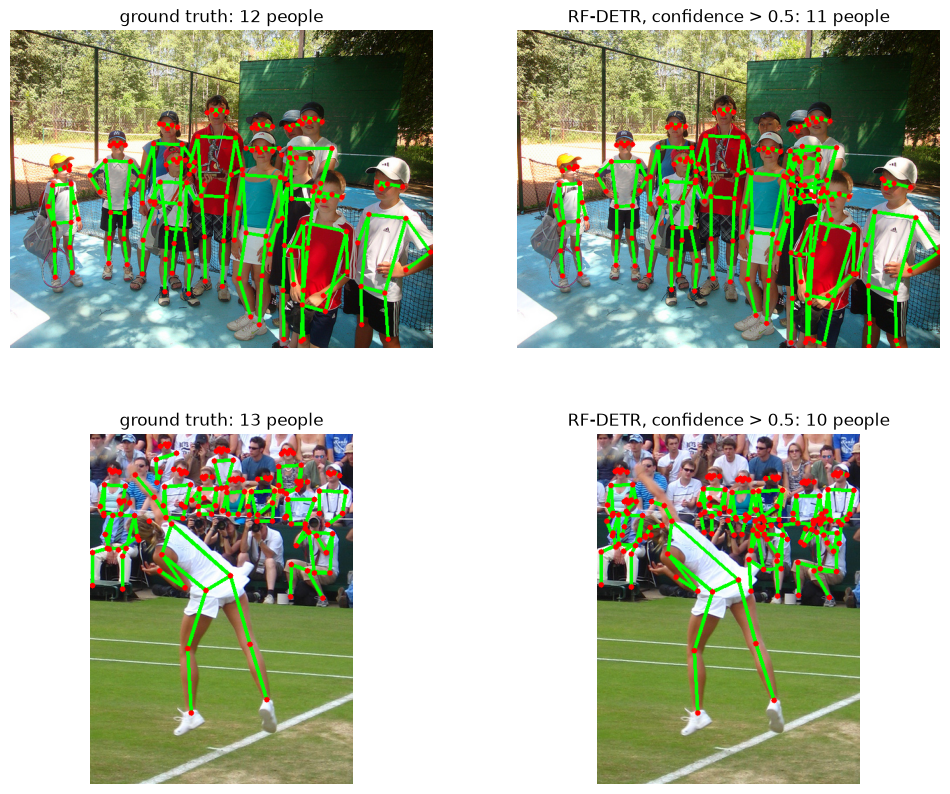

In [7]:
edge_annotator = sv.EdgeAnnotator(color=sv.Color.GREEN, thickness=3)
vertex_annotator = sv.VertexAnnotator(color=sv.Color.RED, radius=4)

# the two images with the most nearly complete skeletons
showcase = sorted(range(len(image_ids)), key=lambda i: -(targets[i].visible.sum(axis=1) >= 12).sum())[:2]

panels, titles = [], []
for index in showcase:
    # supervision annotators and plot_images_grid use OpenCV's BGR channel order
    image = load_image(image_ids[index])[..., ::-1].copy()
    confident = predictions[index][predictions[index].detection_confidence > 0.5]
    labelled = targets[index][targets[index].visible.any(axis=1)]
    for key_points, title in [(labelled, "ground truth"), (confident, "RF-DETR, confidence > 0.5")]:
        panel = edge_annotator.annotate(image.copy(), key_points)
        panels.append(vertex_annotator.annotate(panel, key_points))
        titles.append(f"{title}: {len(key_points)} people")

sv.plot_images_grid(panels, grid_size=(2, 2), titles=titles, size=(12, 10))

## Compute keypoint mAP

`KeyPointMeanAveragePrecision` follows COCO keypoint evaluation: OKS thresholds from 0.50 to 0.95, up to 20 predictions per image, and medium and large buckets only, since COCO keypoint labels cover only people of at least 32² pixels. With 17 keypoints it uses the COCO sigmas, the per-keypoint tolerances in OKS, by default.

In [8]:
metric = KeyPointMeanAveragePrecision()
for image_predictions, image_targets in zip(predictions, targets):
    metric.update(image_predictions, image_targets)
result = metric.compute()
print(result)

Average Precision (AP) @[ OKS=0.50:0.95 | area=   all | maxDets= 20 ] = 0.729
Average Precision (AP) @[ OKS=0.50      | area=   all | maxDets= 20 ] = 0.916
Average Precision (AP) @[ OKS=0.75      | area=   all | maxDets= 20 ] = 0.800
Average Precision (AP) @[ OKS=0.50:0.95 | area=medium | maxDets= 20 ] = 0.664
Average Precision (AP) @[ OKS=0.50:0.95 | area= large | maxDets= 20 ] = 0.820


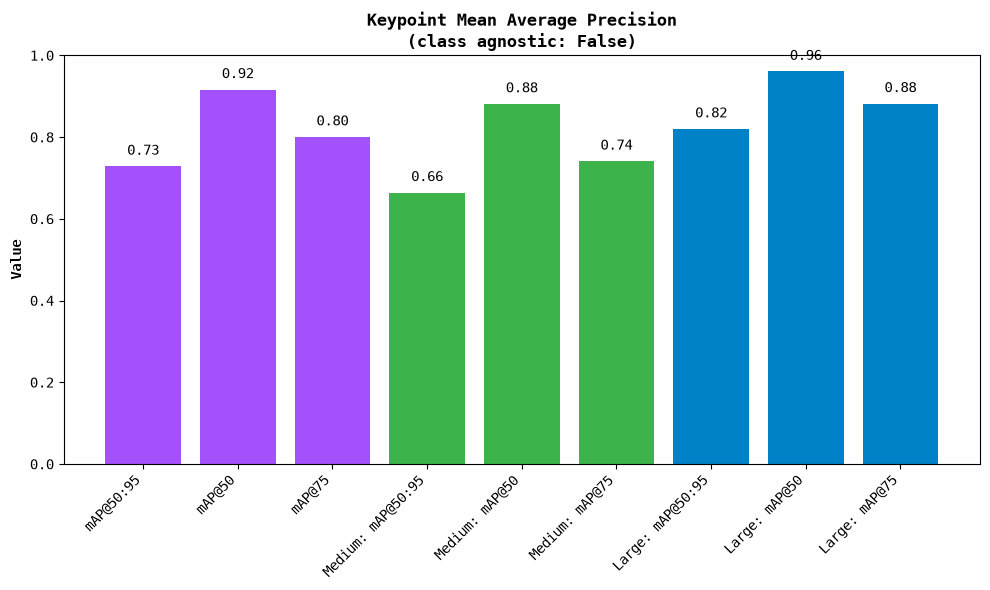

In [9]:
result.plot()

In [10]:
result.to_pandas()

,mAP@50:95,mAP@50,mAP@75,medium_objects_mAP@50:95,medium_objects_mAP@50,medium_objects_mAP@75,large_objects_mAP@50:95,large_objects_mAP@50,large_objects_mAP@75
0,0.728627,0.916205,0.800431,0.664166,0.881373,0.741075,0.820041,0.960664,0.881868


## Two mistakes that change the score silently

Neither mistake below raises a warning: the first returns a lower but plausible score, the second returns 0 for a model that works. Since the predictions are already computed, we can show each one without running the model again.

In [11]:
def keypoint_map(predictions: list[sv.KeyPoints], targets: list[sv.KeyPoints]) -> float:
    metric = KeyPointMeanAveragePrecision()
    for image_predictions, image_targets in zip(predictions, targets):
        metric.update(image_predictions, image_targets)
    return metric.compute().map50_95


# 1. Scoring only the predictions that survive the display threshold
displayed = [p[p.detection_confidence > 0.5] for p in predictions]
print(f"threshold 0.01: mAP50-95 = {result.map50_95:.3f}")
print(f"threshold 0.5:  mAP50-95 = {keypoint_map(displayed, targets):.3f}")

# 2. Targets labelled with class 0 while the model reports COCO id 1
shifted = [
    sv.KeyPoints(xy=t.xy, visible=t.visible, class_id=np.zeros(len(t), dtype=int), data=t.data)
    for t in targets
]
print(f"class ids 1 vs 0: mAP50-95 = {keypoint_map(predictions, shifted):.3f}")

threshold 0.01: mAP50-95 = 0.729
threshold 0.5:  mAP50-95 = 0.658
class ids 1 vs 0: mAP50-95 = 0.000


If your labels and model disagree on ids, remap one side, or pass `class_agnostic=True` to `KeyPointMeanAveragePrecision` when there is a single class.

## Using your own data

*   **A different skeleton.** For anything other than the 17 COCO keypoints, pass one OKS sigma per keypoint: `KeyPointMeanAveragePrecision(sigmas=...)`. Predictions and targets must also list keypoints in the same order.
*   **Images without people.** Pass `sv.KeyPoints.empty()` as the target, so predictions on those images still count as false positives (`coco_to_keypoints` above expects at least one person). This cookbook samples only images with people, which is one reason its score differs from the full benchmark.
*   **No annotated area.** Without `data["area"]` the box spanning a target's visible keypoints is used, so scores may differ from COCO's.
*   **Object size of predictions.** A prediction falls into the medium or large bucket by its box in `data["xyxy"]` when present, otherwise by the box spanning its keypoints. This matches `pycocotools` with and without a result `bbox`.
*   **Other models.** Any source that can be turned into `sv.KeyPoints` works the same way, for example `sv.KeyPoints.from_ultralytics(...)` for YOLO pose models. Check which class ids each source uses.

## Conclusion

Keypoint mAP needs only two lists of `sv.KeyPoints`, but COCO-comparable numbers depend on keeping low-confidence predictions, matching class ids, and passing the annotated area, crowd flags and boxes. For the complete rules, see the [`KeyPointMeanAveragePrecision` docs](https://supervision.roboflow.com/latest/metrics/mean_average_precision/#pose-estimation); for drawing skeletons, see the [keypoint annotators](https://supervision.roboflow.com/latest/keypoint/annotators/).